# Hierarchical Clustering: Customer Spending Analysis
### A step-by-step unsupervised learning notebook

**Dataset:** `customer_spending.csv` (300 customer records)

**Goal:** Group customers with similar characteristics using Agglomerative Hierarchical Clustering.

We will use these features:
- `Age`
- `Annual_Income_PKR`
- `Spending_Score`
- `Visits_Per_Month`
- `Average_Basket_PKR`

This is an **unsupervised learning** task: there is no target column to predict. The model discovers groups from similarities among the selected features.

**Before running:** Keep this notebook and `customer_spending.csv` in the same folder.

## 1. Import libraries

We use pandas and NumPy for data handling, Matplotlib and Seaborn for visualizations, and scikit-learn/SciPy for clustering and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")

## 2. Load the dataset

In [2]:
import os
DATA_PATH = "customer_spending.csv" if os.path.exists("customer_spending.csv") else "Coursework/Machine_Learning/customer_spending.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (300, 5)


,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR
0,44,156378.0,NaN,9.3,12149
1,18,79789.0,60.118149,6.5,3865
2,32,171480.0,97.546152,5.9,11055
3,36,83651.0,45.365218,5.4,5370
4,30,62788.0,39.774119,3.0,2672


## 3. Inspect columns, data types, and missing values

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Values"))

print("\nSummary statistics:")
display(df.describe().T)

Column names:
['Age', 'Annual_Income_PKR', 'Spending_Score', 'Visits_Per_Month', 'Average_Basket_PKR']

Data types:


,Data Type
Age,int64
Annual_Income_PKR,float64
Spending_Score,float64
Visits_Per_Month,float64
Average_Basket_PKR,int64



Missing values:


,Missing Values
Age,0
Annual_Income_PKR,3
Spending_Score,3
Visits_Per_Month,0
Average_Basket_PKR,0



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Age,300.0,35.870000,11.375020,18.000000,27.000000,34.500000,44.000000,64.000000
Annual_Income_PKR,297.0,87929.717172,53860.547858,15000.000000,44842.000000,77609.000000,120445.000000,258335.000000
Spending_Score,297.0,52.815193,23.864726,3.192915,31.896917,53.658754,74.267146,99.644361
Visits_Per_Month,300.0,5.417333,2.969066,0.000000,2.700000,5.500000,7.800000,13.500000
Average_Basket_PKR,300.0,4609.500000,3114.903934,322.000000,2074.750000,3830.500000,5821.000000,12530.000000


### What should you notice?

- Each row represents a customer.
- The dataset contains 300 rows and five numeric features.
- `Annual_Income_PKR` and `Spending_Score` contain a small number of missing values.
- Missing values need to be handled before scaling and clustering.

## 4. Exploratory data analysis (EDA)

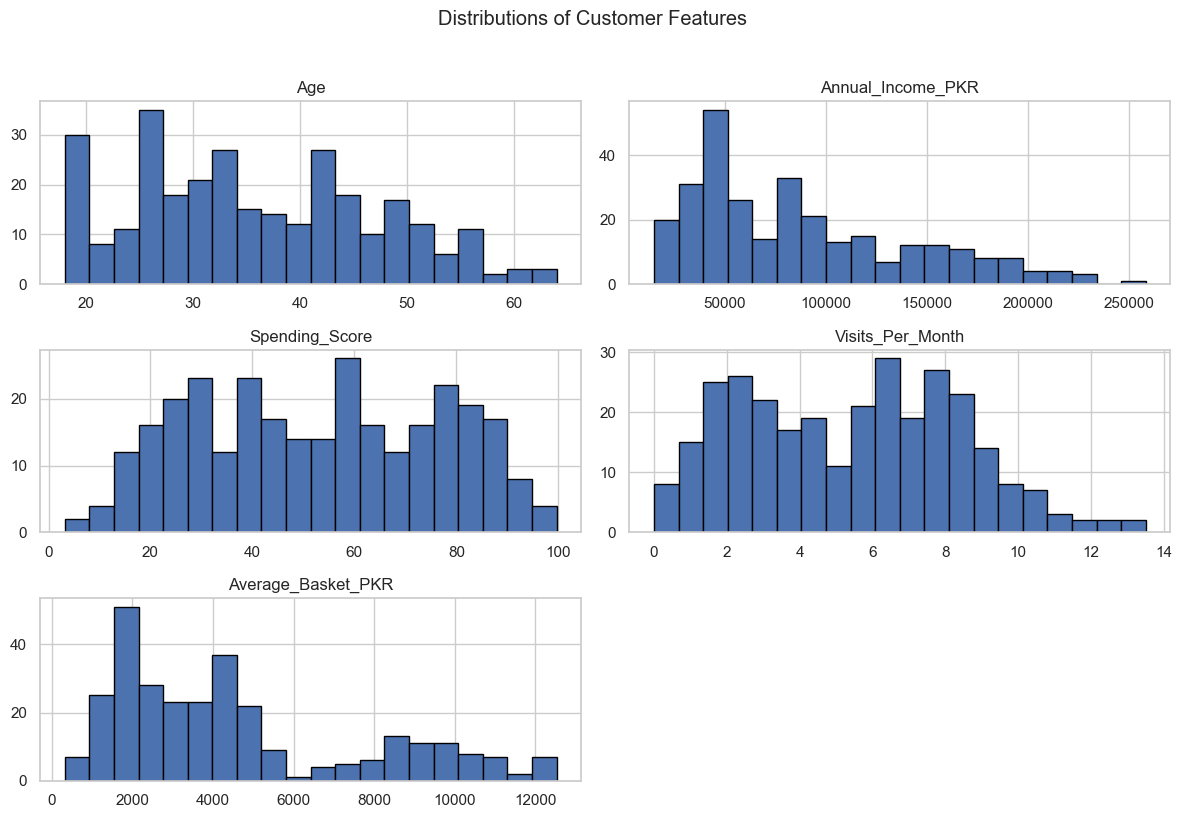

In [4]:
df.hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distributions of Customer Features", y=1.02)
plt.tight_layout()
plt.show()

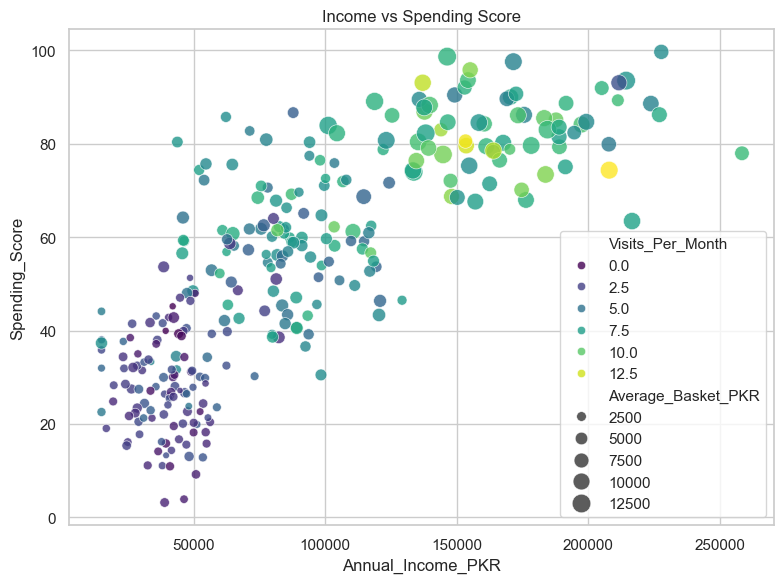

In [5]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Annual_Income_PKR",
    y="Spending_Score",
    hue="Visits_Per_Month",
    palette="viridis",
    size="Average_Basket_PKR",
    sizes=(20, 180),
    alpha=0.8
)
plt.title("Income vs Spending Score")
plt.tight_layout()
plt.show()

**Discussion:** EDA helps us understand the range and shape of each feature. The scatter plot only shows selected dimensions; hierarchical clustering will consider all five selected features.

## 5. Prepare features: impute missing values and scale

Hierarchical clustering relies on distances. Since income and basket value are measured in PKR while age and spending score use different scales, scaling is important. Otherwise, large-number features can dominate the distance calculation.

We use median imputation for missing numeric values, then standardize each feature.

In [6]:
features = [
    "Age",
    "Annual_Income_PKR",
    "Spending_Score",
    "Visits_Per_Month",
    "Average_Basket_PKR"
]

X = df[features].copy()

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Shape after preprocessing:", X_scaled.shape)
print("Any missing values after imputation:", np.isnan(X_scaled).any())

Shape after preprocessing: (300, 5)
Any missing values after imputation: False


## 6. Understand hierarchical clustering

Agglomerative hierarchical clustering is a **bottom-up** approach:

1. Initially, every customer is treated as its own cluster.
2. The algorithm merges the two closest clusters.
3. It repeats this process until all customers are joined into one hierarchy.
4. We choose a cut level in the hierarchy to obtain the desired number of clusters.

**Linkage** defines how distance between clusters is calculated. Ward linkage merges clusters in a way that minimizes the increase in within-cluster variance. For this example, we use Ward linkage with Euclidean distance.

## 7. Build and read a dendrogram

A dendrogram visualizes the sequence of merges. The vertical axis represents linkage distance. Large vertical jumps can suggest places to cut the tree, but the dendrogram should be interpreted alongside cluster quality and business usefulness.

With 300 records, the full dendrogram can be crowded, so the plot below is truncated to show the last levels of merging.

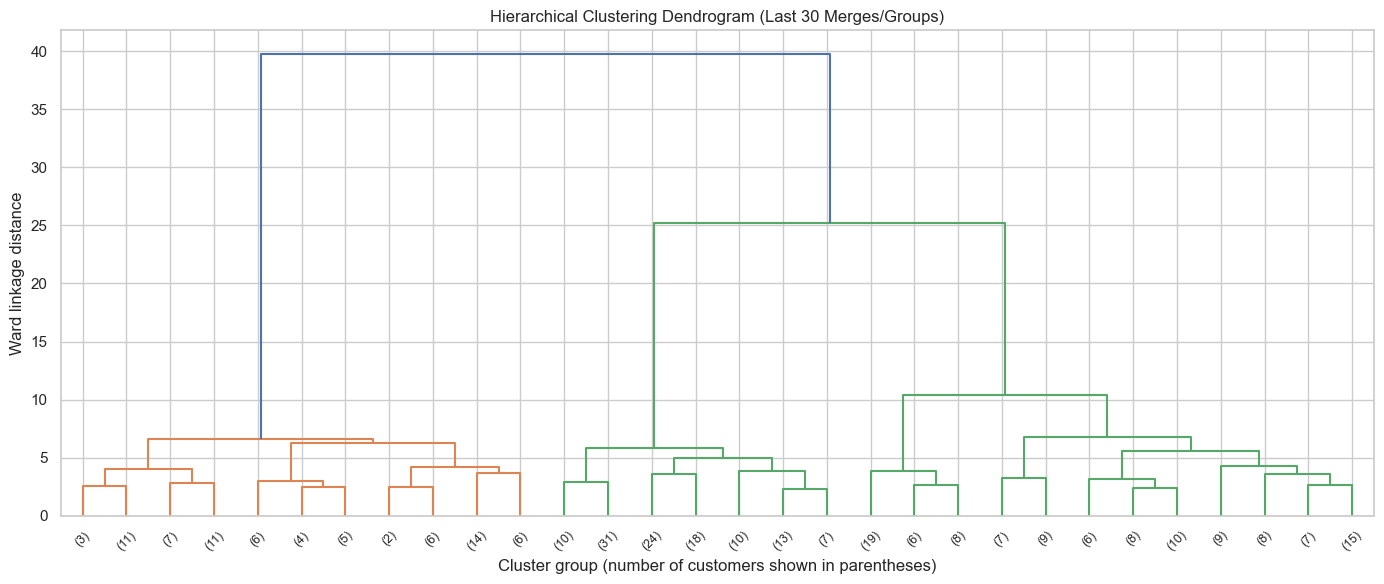

In [7]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45,
    leaf_font_size=9
)
plt.title("Hierarchical Clustering Dendrogram (Last 30 Merges/Groups)")
plt.xlabel("Cluster group (number of customers shown in parentheses)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

### How to interpret it

- Each branch merge combines two customers or existing groups.
- Merges at lower heights join relatively similar groups.
- Merges at much greater heights combine groups that are more different.
- A horizontal cut across the dendrogram determines how many clusters remain.

The dendrogram does not automatically declare the best K. It helps you identify plausible values to test.

## 8. Compare different numbers of clusters using Silhouette Score

Silhouette Score measures how well-separated and cohesive the clusters are. It ranges from -1 to +1; higher is generally better.

We will test K = 2 through K = 8. This is a useful comparison, not a guarantee that the highest score is always the most meaningful business solution.

In [8]:
results = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    results.append({
        "K": k,
        "Silhouette_Score": score
    })

scores_df = pd.DataFrame(results).sort_values("K")
display(scores_df.round(3))

,K,Silhouette_Score
0,2,0.481
1,3,0.450
2,4,0.401
3,5,0.372
4,6,0.314
5,7,0.320
6,8,0.190


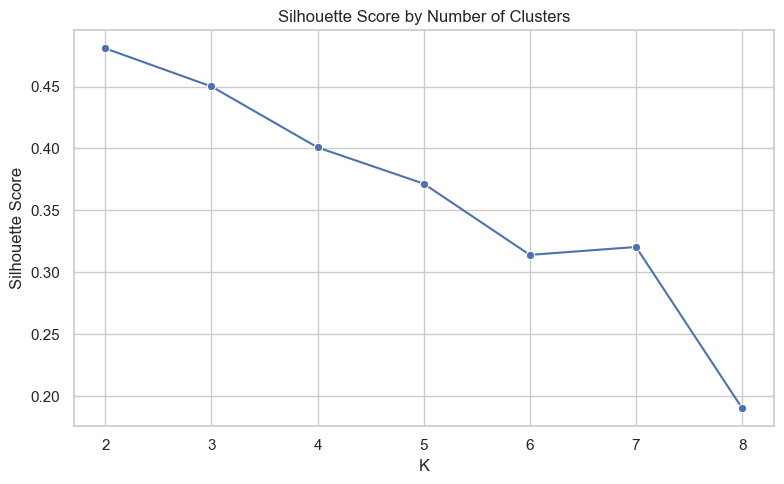

K with the highest silhouette score among tested values: 2


In [9]:
plt.figure(figsize=(8, 5))
sns.lineplot(data=scores_df, x="K", y="Silhouette_Score", marker="o")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(scores_df["K"])
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

best_k = int(scores_df.loc[scores_df["Silhouette_Score"].idxmax(), "K"])
print("K with the highest silhouette score among tested values:", best_k)

**Important:** Silhouette score is one input to choosing K. Also inspect the dendrogram, cluster sizes, customer profiles, and whether the groups are useful. For learning, you can compare the best-scoring K with K = 3.

## 9. Fit the final hierarchical clustering model

In [10]:
# Start with the best K from the tested silhouette scores.
# Change this value if dendrogram interpretation or business needs support another K.
chosen_k = best_k

final_model = AgglomerativeClustering(
    n_clusters=chosen_k,
    linkage="ward",
    metric="euclidean"
)

df_clustered = df.copy()
df_clustered["Cluster"] = final_model.fit_predict(X_scaled)

print("Chosen number of clusters:", chosen_k)
display(df_clustered.head(10))

Chosen number of clusters: 2


,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR,Cluster
0,44,156378.0,NaN,9.3,12149,1
1,18,79789.0,60.118149,6.5,3865,0
2,32,171480.0,97.546152,5.9,11055,1
3,36,83651.0,45.365218,5.4,5370,0
4,30,62788.0,39.774119,3.0,2672,0
5,50,188980.0,79.330861,9.1,8245,1
6,54,118759.0,89.041153,8.6,11608,1
7,52,223723.0,88.576972,5.9,9379,1
8,20,35781.0,43.112284,3.3,1451,0
9,30,85721.0,43.401278,4.8,4481,0


## 10. Check cluster sizes

In [11]:
cluster_sizes = (
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Number_of_Customers")
)
display(cluster_sizes)

,Number_of_Customers
Cluster,
0,225
1,75


Cluster labels such as 0, 1, and 2 are **arbitrary identifiers**, not rankings. Cluster 2 is not inherently better or worse than Cluster 0.

## 11. Profile the clusters

We calculate average values for each feature within each cluster. These profiles help translate mathematical groups into understandable customer segments.

In [12]:
cluster_profiles = df_clustered.groupby("Cluster")[features].mean().round(2)
display(cluster_profiles)

,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR
Cluster,,,,,
0,32.44,61598.82,43.06,4.38,3017.28
1,46.17,165869.19,82.23,8.53,9386.15


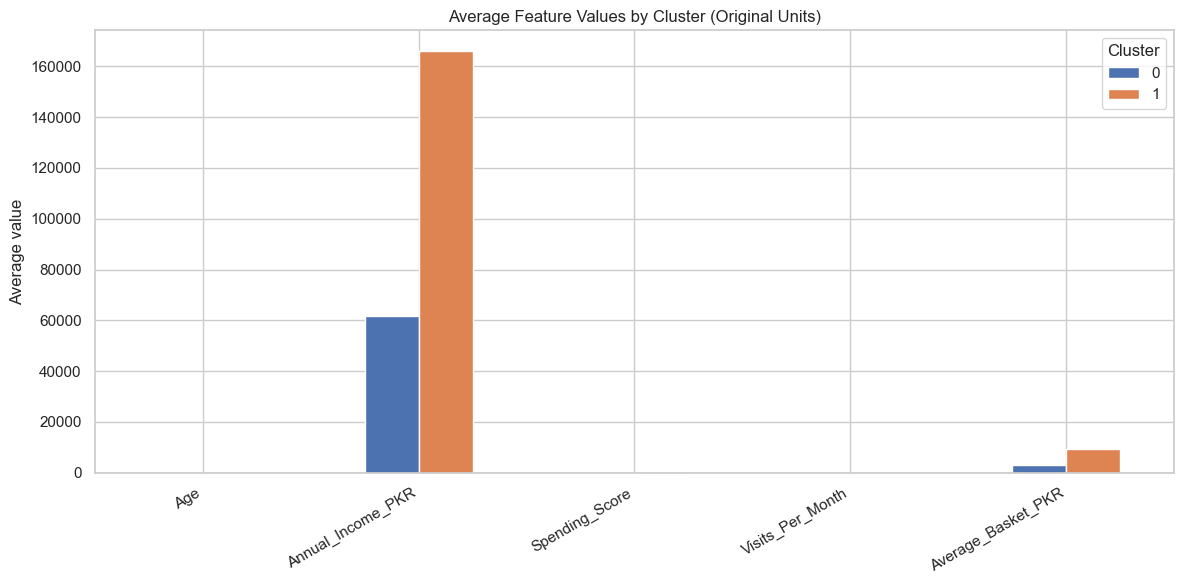

In [13]:
cluster_profiles.T.plot(kind="bar", figsize=(12, 6))
plt.title("Average Feature Values by Cluster (Original Units)")
plt.ylabel("Average value")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

**Interpret carefully:** Features use different units, so the bar chart's raw scales are not directly comparable across features. Use the profile table to compare customers within each feature. You may also describe each cluster relative to the overall average.

In [14]:
overall_means = df[features].mean()
relative_profiles = cluster_profiles.divide(overall_means, axis=1).round(2)
display(relative_profiles)

,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR
Cluster,,,,,
0,0.90,0.70,0.82,0.81,0.65
1,1.29,1.89,1.56,1.57,2.04


A relative value above 1 means that the cluster average is above the dataset-wide average for that feature; below 1 means it is below the overall average. Because the source data has missing values, means are calculated using available values.

## 12. Visualize clusters in two dimensions with PCA

PCA compresses the five scaled features into two dimensions for visualization. It does not change the cluster labels; it provides a simplified view of the data. Some information is lost when reducing dimensions.

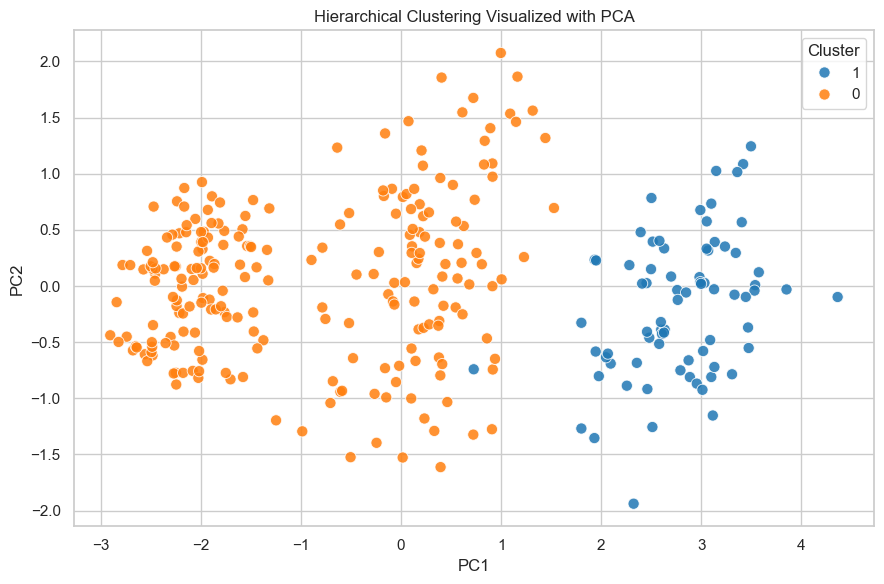

Variance explained by the two PCA components: 0.861


In [15]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": df_clustered["Cluster"].astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=65,
    alpha=0.85
)
plt.title("Hierarchical Clustering Visualized with PCA")
plt.tight_layout()
plt.show()

print("Variance explained by the two PCA components:",
      round(pca.explained_variance_ratio_.sum(), 3))

## 13. Save the results

In [16]:
output_file = "customer_spending_hierarchical_clusters.csv"
df_clustered.to_csv(output_file, index=False)
print(f"Saved clustered dataset to: {output_file}")

Saved clustered dataset to: customer_spending_hierarchical_clusters.csv


## 14. Key differences: K-Means vs Hierarchical Clustering

| K-Means | Hierarchical clustering |
|---|---|
| Requires K before fitting. | Can explore the hierarchy using a dendrogram before selecting a cut. |
| Iteratively updates cluster centroids. | Agglomerative clustering repeatedly merges groups. |
| Often efficient for larger datasets. | Can be more computationally expensive as datasets grow. |
| Output includes cluster labels and centroids. | Output includes cluster labels; the dendrogram represents merge history. |

Both methods are distance-sensitive, so feature selection and scaling matter. Results can change with different features, scaling methods, linkage methods, and K.

## 15. Practice tasks

1. Run the model with `chosen_k = 2`, `3`, and `4`. Compare cluster sizes and profiles.
2. Change linkage from `"ward"` to `"complete"` or `"average"`. For non-Ward linkages, test whether the silhouette scores change.
3. Create a scatter plot of `Annual_Income_PKR` vs `Average_Basket_PKR`, colored by cluster.
4. Describe each cluster in plain language using its profile. Avoid assigning names based only on the numeric cluster label.
5. Explain why scaling is important for this dataset.
6. Compare the silhouette score with the dendrogram and decide which K you would recommend, with a short justification.

## 16. Summary

- Hierarchical clustering discovers groups without a target label.
- Agglomerative clustering builds a bottom-up hierarchy by merging clusters.
- A dendrogram helps visualize the merge structure and consider where to cut the tree.
- Scaling is important because the features use different units and ranges.
- Silhouette Score helps compare candidate K values.
- Cluster profiles help interpret what the groups mean in a customer-spending context.

**Remember:** The best clustering solution is not just the one with the best metric; it should also be interpretable and useful for the intended business question.